# E234 · Replay memory admission under a 64-image limit

**Complete** · E234 pilot finished · full-run gate stayed closed  
Updated 2026-11-23T13:05:32+01:00 Stockholm

Each walk is a fresh BDD A → B → A sequence with separate raw A/B holdouts. All arms share the same A-trained checkpoint and run the same 384 optimizer steps after A. Four paired independent mask draws per walk hold exposure fixed at 576 incoming and 192 historical image slots. All policies draw 48 distinct retained images per segment with the same sampler. A bank can retain at most 64 observed images, and evicted images never re-enter it.

Uniform uses per-image reservoir admission. FIFO retains the latest observations. Frozen-feature coverage chooses observations to cover frozen embedding space among retained and presently buffered frames. Online regime retention matches each buffer to earlier frozen-feature centroids or opens a new group when sufficiently distant. Its 64 slots are divided evenly among discovered groups, with uniform admission within each group. These policies update after each 192-arrival buffer using observed frames only.

The endpoint gate is the equally weighted A/B mean of scene, weather, traffic-light and pedestrian balanced accuracy. A policy must beat uniform reservoir by at least +0.25 pp on four independent pilot walks. A qualifying policy then faces the reservoir on eight fresh walks and a separate annotated validation pool. Walk-level intervals quantify uncertainty in both phases. Raw capture selection and memory admission use no semantic labels. Lighting is outside the score.

The frozen-feature regime trigger is a cosine distance of **0.0219**. It was fixed from the 90th percentile of within-clip changes on 24 archived E233 clips.

## Pilot · 4 walks complete

| Walk | Frozen A/B distance | Minimum A class count | Minimum B class count |
| --- | --- | --- | --- |
| 1 | 0.717 | 10 | 15 |
| 2 | 0.302 | 11 | 11 |
| 3 | 0.118 | 11 | 13 |
| 4 | 0.473 | 12 | 12 |

| Admission | B acquisition (pp) | B retention on A return (pp) | B consolidation (pp) | Final A/B vs uniform (pp) |
| --- | --- | --- | --- | --- |
| Uniform reservoir | -0.933 [-1.726, +0.124] | +1.018 [+0.850, +1.186] | +0.085 [-0.754, +1.327] | +0.000 [+0.000, +0.000] |
| FIFO eviction | -1.457 [-2.048, -0.758] | +1.445 [+1.084, +1.782] | -0.012 [-0.492, +0.558] | -0.060 [-0.466, +0.270] |
| Frozen-feature coverage | -0.604 [-1.459, +0.524] | +0.517 [-0.332, +1.256] | -0.087 [-1.507, +1.333] | -0.118 [-0.348, +0.100] |
| Online regime-aware retention | -1.016 [-1.728, -0.145] | +0.993 [+0.742, +1.280] | -0.023 [-0.839, +1.204] | +0.014 [-0.097, +0.124] |

| Admission | B acquisition vs uniform (pp) | B retention vs uniform (pp) | B consolidation vs uniform (pp) |
| --- | --- | --- | --- |
| FIFO eviction | -0.523 [-1.003, -0.047] | +0.427 [+0.036, +0.817] | -0.097 [-0.800, +0.310] |
| Frozen-feature coverage | +0.330 [+0.255, +0.400] | -0.502 [-1.387, +0.329] | -0.172 [-1.143, +0.704] |
| Online regime-aware retention | -0.082 [-0.269, +0.024] | -0.025 [-0.222, +0.172] | -0.107 [-0.271, +0.086] |

**Pilot gate stayed closed.** Every alternative fell below +0.25 pp over uniform.

| Bank before segment | Segment | Initial A slots | B slots | Return A slots | Mean age (arrivals) |
| --- | --- | --- | --- | --- | --- |
| Uniform reservoir | 1 | 64.0 | 0.0 | 0.0 | 197.1 |
| Uniform reservoir | 2 | 42.0 | 22.0 | 0.0 | 287.3 |
| Uniform reservoir | 3 | 31.6 | 32.4 | 0.0 | 385.3 |
| Uniform reservoir | 4 | 25.2 | 26.6 | 12.2 | 481.9 |
| FIFO eviction | 1 | 64.0 | 0.0 | 0.0 | 32.5 |
| FIFO eviction | 2 | 0.0 | 64.0 | 0.0 | 32.5 |
| FIFO eviction | 3 | 0.0 | 64.0 | 0.0 | 32.5 |
| FIFO eviction | 4 | 0.0 | 0.0 | 64.0 | 32.5 |
| Frozen-feature coverage | 1 | 64.0 | 0.0 | 0.0 | 188.2 |
| Frozen-feature coverage | 2 | 60.0 | 4.0 | 0.0 | 361.8 |
| Frozen-feature coverage | 3 | 51.2 | 12.8 | 0.0 | 483.0 |
| Frozen-feature coverage | 4 | 37.2 | 9.0 | 17.8 | 514.8 |
| Online regime-aware retention | 1 | 64.0 | 0.0 | 0.0 | 197.1 |
| Online regime-aware retention | 2 | 32.0 | 32.0 | 0.0 | 244.1 |
| Online regime-aware retention | 3 | 32.0 | 32.0 | 0.0 | 389.0 |
| Online regime-aware retention | 4 | 21.5 | 23.8 | 18.8 | 431.2 |

| Admission | Bank maintenance s | Replay sampling s | MAE training s |
| --- | --- | --- | --- |
| Uniform reservoir | 0.005 | 0.002 | 3.627 |
| FIFO eviction | 0.002 | 0.002 | 3.555 |
| Frozen-feature coverage | 0.031 | 0.002 | 3.566 |
| Online regime-aware retention | 0.029 | 0.002 | 3.561 |

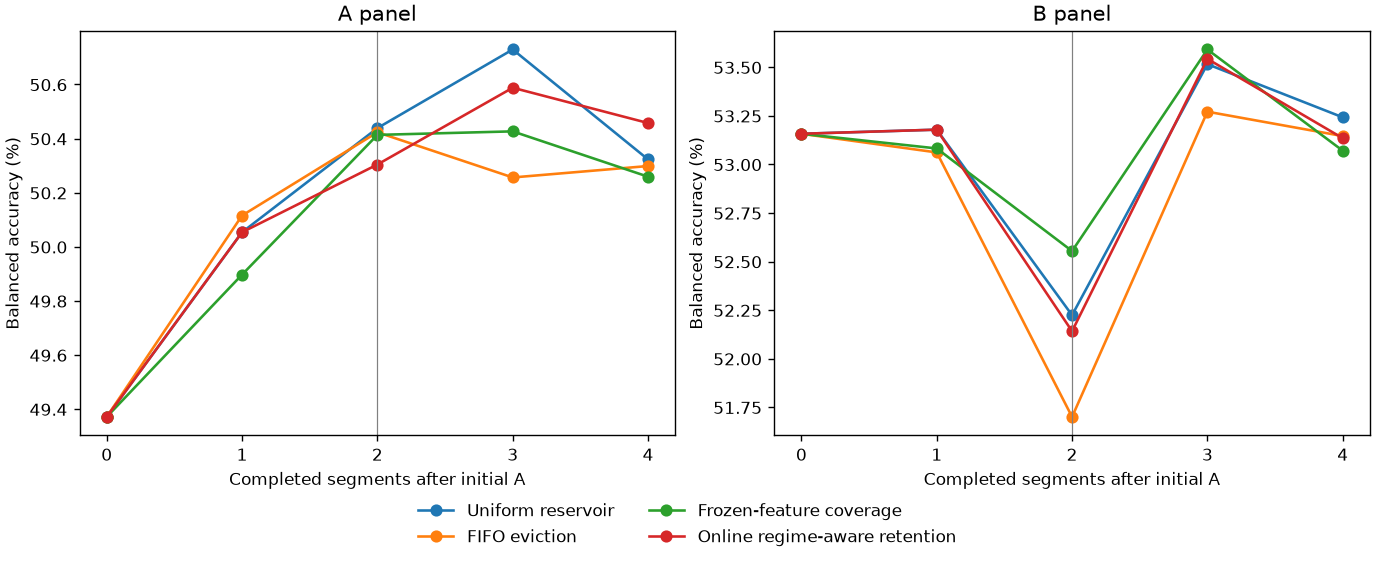